<a href="https://colab.research.google.com/github/Chaki34/Research-paper/blob/main/CAFNet_Brain_Tumor_Classification_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAFNet: MobileNetV2 + Vision Transformer + Cross-Attention Fusion
### Brain Tumor MRI Classification — Google Colab

This notebook implements a reproducible CAFNet-style pipeline for the Kaggle dataset:
https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset

**Classes:** glioma, meningioma, notumor, pituitary.

**Research basis:** Jayaraman et al., *Scientific Reports* (2025), DOI: 10.1038/s41598-025-28636-9.

> Accuracy cannot be guaranteed. The paper reports 96.41% in its abstract/ablation results (the conclusion reports 96.81%). This notebook reports the actual held-out test result from your run; do not tune on the test set.
>
> The paper's original dataset counts (5,712 train / 1,311 test) do not match all current Kaggle dataset revisions. This notebook inspects the downloaded version and uses its provided `Training/` and `Testing/` folders as separate splits. Validation is carved from `Training/` only.

## 1. Runtime setup
In Colab, select **Runtime → Change runtime type → T4 GPU** (or better).

In [1]:
!pip -q install kagglehub scikit-learn seaborn

In [2]:
import os, random, pathlib, json, math, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the Kaggle dataset

This uses KaggleHub. If Kaggle asks for authentication, follow the KaggleHub authentication prompt in Colab, or upload `kaggle.json` from your Kaggle account and configure the Kaggle API.

In [3]:
import kagglehub

DATASET_HANDLE = "masoudnickparvar/brain-tumor-mri-dataset"
dataset_path = kagglehub.dataset_download(DATASET_HANDLE)
print("Downloaded to:", dataset_path)

# Find the directory containing Training/ and Testing/
root = pathlib.Path(dataset_path)
candidates = [p for p in [root, *root.rglob("*")] if p.is_dir()
              and (p / "Training").is_dir() and (p / "Testing").is_dir()]
if not candidates:
    raise FileNotFoundError(
        "Could not find Training/ and Testing/ folders. Inspect dataset_path and update DATA_ROOT."
    )
DATA_ROOT = candidates[0]
TRAIN_DIR = DATA_ROOT / "Training"
TEST_DIR = DATA_ROOT / "Testing"
print("DATA_ROOT:", DATA_ROOT)
print("Training classes:", sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir()]))
print("Testing classes:", sorted([p.name for p in TEST_DIR.iterdir() if p.is_dir()]))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Downloaded to: /kaggle/input/brain-tumor-mri-dataset
DATA_ROOT: /kaggle/input/brain-tumor-mri-dataset
Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 3. Inspect class distribution and image dimensions

In [4]:
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_files(folder):
    return [p for p in pathlib.Path(folder).rglob("*")
            if p.is_file() and p.suffix.lower() in VALID_EXTS]

for split_dir in [TRAIN_DIR, TEST_DIR]:
    print("\\n", split_dir.name)
    total = 0
    for class_dir in sorted([p for p in split_dir.iterdir() if p.is_dir()]):
        n = len(image_files(class_dir))
        total += n
        print(f"{class_dir.name:15s}: {n}")
    print("Total:", total)

\n Training
glioma         : 1400
meningioma     : 1400
notumor        : 1400
pituitary      : 1400
Total: 5600
\n Testing
glioma         : 400
meningioma     : 400
notumor        : 400
pituitary      : 400
Total: 1600


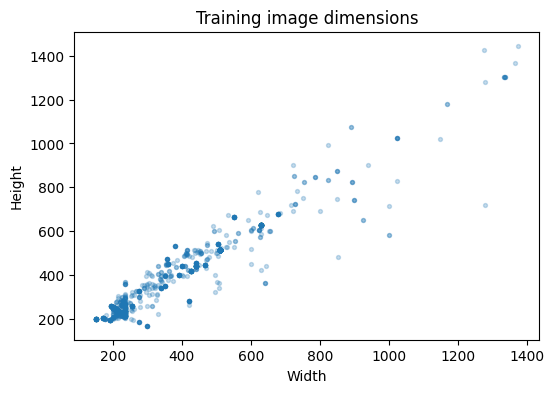

In [5]:
from PIL import Image
dims = []
for p in image_files(TRAIN_DIR):
    try:
        with Image.open(p) as im:
            dims.append(im.size)
    except Exception:
        pass
widths, heights = zip(*dims)
plt.figure(figsize=(6,4))
plt.scatter(widths, heights, alpha=.25, s=8)
plt.xlabel("Width"); plt.ylabel("Height"); plt.title("Training image dimensions")
plt.show()

## 4. Build training, validation and test datasets

The notebook keeps the Kaggle `Testing/` directory untouched for final evaluation. A validation subset is taken from `Training/` using a fixed seed. All images are resized to 128×128 and converted to RGB so that MobileNetV2 can use its ImageNet weights. Pixel scaling is handled by `mobilenet_v2.preprocess_input` inside the model.

Training augmentation: small rotations, zoom, translation and horizontal flips. Validation and test data are not augmented.

In [6]:
IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

class_names = sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir()])
NUM_CLASSES = len(class_names)
assert NUM_CLASSES == 4, f"Expected four classes; found {class_names}"
print("Class order:", class_names)

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="int",
    class_names=class_names, validation_split=0.20, subset="training",
    seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    color_mode="rgb", shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="int",
    class_names=class_names, validation_split=0.20, subset="validation",
    seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    color_mode="rgb", shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, labels="inferred", label_mode="int",
    class_names=class_names, image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, color_mode="rgb", shuffle=False
)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Class order: ['glioma', 'meningioma', 'notumor', 'pituitary']
Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Train batches: 140
Validation batches: 35
Test batches: 50


## 5. Visualize sample MRI images

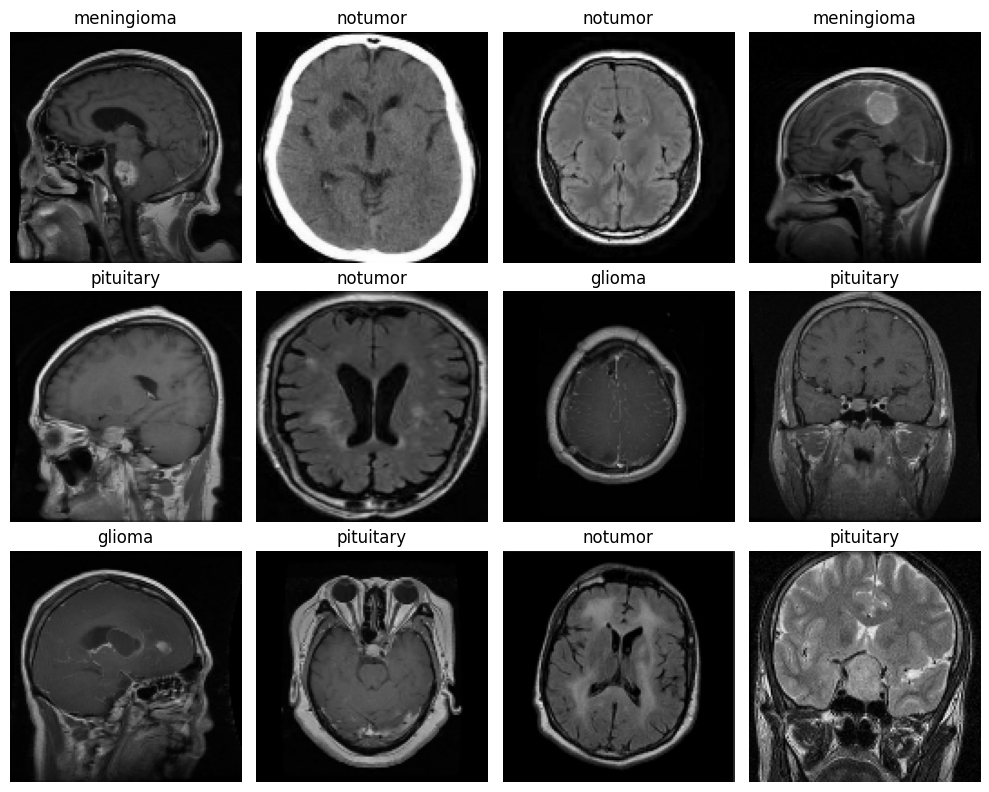

In [7]:
plt.figure(figsize=(10,8))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Define reusable augmentation and transformer blocks

The ViT branch divides the 128×128 image into 16×16 patches (64 tokens), projects each patch to an embedding, adds positional embeddings, and applies Transformer encoder blocks. The paper describes patch extraction, linear projection, positional information and self-attention, but does not clearly specify every ViT hyperparameter; these are explicit reproducibility choices for this implementation.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
], name="data_augmentation")

class PatchEmbedding(layers.Layer):
    def __init__(self, image_size=128, patch_size=16, embed_dim=192, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        self.projection = layers.Conv2D(
            embed_dim, kernel_size=patch_size, strides=patch_size, padding="valid"
        )
        self.position_embedding = layers.Embedding(
            input_dim=self.num_patches, output_dim=embed_dim
        )

    def call(self, images):
        x = self.projection(images)
        x = tf.reshape(x, [tf.shape(x)[0], self.num_patches, -1])
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return x + self.position_embedding(positions)

class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim=192, num_heads=4, mlp_dim=384, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.attn = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads, dropout=dropout
        )
        self.drop1 = layers.Dropout(dropout)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.mlp = keras.Sequential([
            layers.Dense(mlp_dim, activation=tf.nn.gelu),
            layers.Dropout(dropout),
            layers.Dense(embed_dim),
            layers.Dropout(dropout)
        ])

    def call(self, x, training=False):
        a = self.attn(self.norm1(x), self.norm1(x), training=training)
        x = x + self.drop1(a, training=training)
        return x + self.mlp(self.norm2(x), training=training)

## 7. Implement the three ablation configurations

We will compare:
1. MobileNetV2 only.
2. ViT only.
3. MobileNetV2 + ViT with simple feature concatenation.
4. **CAFNet:** MobileNetV2 + ViT + cross-attention.

The CNN branch uses ImageNet-pretrained MobileNetV2. The ViT branch is trained on this MRI dataset. In CAF, ViT tokens act as queries and CNN spatial feature tokens provide keys and values. This is a cross-attention fusion design consistent with the paper's local/global fusion idea.

In [9]:
def build_cnn_backbone(inputs, trainable=False):
    # MobileNetV2 expects RGB input; preprocessing is applied inside the model.
    x = layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input,
        name="mobilenet_preprocess"
    )(inputs)
    backbone = tf.keras.applications.MobileNetV2(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    backbone.trainable = trainable
    features = backbone(x)
    return backbone, features

def build_vit_tokens(inputs, embed_dim=192, depth=4, num_heads=4):
    # Inputs are in [0,255]; normalize to [0,1] for the transformer branch.
    x = layers.Rescaling(1./255.0, name="vit_rescale")(inputs)
    x = PatchEmbedding(IMG_SIZE, 16, embed_dim, name="patch_embedding")(x)
    for i in range(depth):
        x = TransformerBlock(embed_dim, num_heads, embed_dim*2,
                             name=f"vit_encoder_{i+1}")(x)
    return layers.LayerNormalization(epsilon=1e-6, name="vit_final_norm")(x)

def make_classifier(x, num_classes=NUM_CLASSES, name="classifier"):
    x = layers.GlobalAveragePooling1D()(x) if len(x.shape) == 3 else x
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return outputs

def build_model(mode="caf"):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="mri_image")
    augmented = data_augmentation(inputs)

    if mode in ("mobilenet", "concat", "caf"):
        backbone, cnn_map = build_cnn_backbone(augmented, trainable=False)
        cnn_tokens = layers.Reshape((-1, cnn_map.shape[-1]), name="cnn_spatial_tokens")(cnn_map)

    if mode in ("vit", "concat", "caf"):
        vit_tokens = build_vit_tokens(augmented)

    if mode == "mobilenet":
        x = layers.GlobalAveragePooling2D()(cnn_map)
        outputs = make_classifier(x)
    elif mode == "vit":
        outputs = make_classifier(vit_tokens)
    elif mode == "concat":
        cnn_vec = layers.GlobalAveragePooling1D()(cnn_tokens)
        vit_vec = layers.GlobalAveragePooling1D()(vit_tokens)
        fused = layers.Concatenate()([cnn_vec, vit_vec])
        outputs = make_classifier(fused)
    elif mode == "caf":
        # Cross attention: ViT queries attend to CNN keys/values.
        q = layers.Dense(192, name="caf_query_projection")(vit_tokens)
        k = layers.Dense(192, name="caf_key_projection")(cnn_tokens)
        v = layers.Dense(192, name="caf_value_projection")(cnn_tokens)
        attended = layers.MultiHeadAttention(
            num_heads=4, key_dim=48, dropout=0.1, name="cross_attention"
        )(query=q, key=k, value=v)
        attended = layers.LayerNormalization(epsilon=1e-6)(q + attended)
        fused_tokens = layers.Concatenate(axis=-1, name="caf_feature_fusion")(
            [vit_tokens, attended]
        )
        fused_tokens = layers.Dense(256, activation="gelu")(fused_tokens)
        outputs = make_classifier(fused_tokens)
    else:
        raise ValueError("mode must be mobilenet, vit, concat, or caf")

    model = keras.Model(inputs, outputs, name=f"{mode}_brain_tumor_model")
    return model, (backbone if mode in ("mobilenet", "concat", "caf") else None)

## 8. Training utilities

Use early stopping and learning-rate reduction based on validation loss. The test set is not used for checkpoint selection or hyperparameter tuning. Class weights are calculated from the training split only.

In [10]:
y_train = np.concatenate([y.numpy() for _, y in train_ds], axis=0)
weights = compute_class_weight(
    class_weight="balanced", classes=np.arange(NUM_CLASSES), y=y_train
)
class_weights = {i: float(w) for i, w in enumerate(weights)}
print("Class weights:", class_weights)

def compile_model(model, lr=1e-4):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

def callbacks_for(name):
    return [
        keras.callbacks.ModelCheckpoint(
            f"{name}_best.keras", monitor="val_accuracy",
            mode="max", save_best_only=True, verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=7, restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=3,
            min_lr=1e-7, verbose=1
        )
    ]

def train_model(mode, epochs=30, lr=1e-4):
    model, backbone = build_model(mode)
    compile_model(model, lr)
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=epochs,
        class_weight=class_weights, callbacks=callbacks_for(mode)
    )
    return model, history, backbone

Class weights: {0: 0.9824561403508771, 1: 0.9955555555555555, 2: 1.018181818181818, 3: 1.0044843049327354}


## 9. Train the proposed CAFNet

Start with the frozen ImageNet MobileNetV2 feature extractor while training the transformer, fusion layer and classifier. Then fine-tune the last part of MobileNetV2 at a very low learning rate. This two-stage schedule is a practical training choice; the article does not provide a complete reproducible hyperparameter table.

In [11]:
caf_model, caf_history, caf_backbone = train_model("caf", epochs=30, lr=1e-4)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4508 - loss: 1.1798
Epoch 1: val_accuracy improved from None to 0.95089, saving model to caf_best.keras

Epoch 1: finished saving model to caf_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 117ms/step - accuracy: 0.6187 - loss: 0.8802 - val_accuracy: 0.9509 - val_loss: 0.1782 - learning_rate: 1.0000e-04
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.8195 - loss: 0.4753
Epoch 2: val_accuracy improved from 0.95089 to 0.95982, saving model to caf_best.keras

Epoch 2: finished saving model to caf_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.8275 - loss: 0.4516 - val_accuracy: 0.9598 - val_loss: 0.1544 - learning_rate: 1.0000e-04
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8566 - loss: 0.4001
Epoch 3: val_accuracy did not improve from 0.95982
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - accuracy: 0.8629 - loss: 0.3

In [12]:
# Fine-tune only the later MobileNetV2 layers.
caf_backbone.trainable = True
for layer in caf_backbone.layers[:-30]:
    layer.trainable = False
# Keep BatchNorm layers frozen for stable fine-tuning on a modest dataset.
for layer in caf_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(caf_model, lr=1e-5)
fine_tune_history = caf_model.fit(
    train_ds, validation_data=val_ds, epochs=15,
    class_weight=class_weights, callbacks=callbacks_for("caf_finetuned")
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9290 - loss: 0.1933
Epoch 1: val_accuracy improved from None to 0.98214, saving model to caf_finetuned_best.keras

Epoch 1: finished saving model to caf_finetuned_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 38s 122ms/step - accuracy: 0.9315 - loss: 0.1837 - val_accuracy: 0.9821 - val_loss: 0.0610 - learning_rate: 1.0000e-05
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9362 - loss: 0.1687
Epoch 2: val_accuracy improved from 0.98214 to 0.99018, saving model to caf_finetuned_best.keras

Epoch 2: finished saving model to caf_finetuned_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.9386 - loss: 0.1642 - val_accuracy: 0.9902 - val_loss: 0.0413 - learning_rate: 1.0000e-05
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9386 - loss: 0.1646
Epoch 3: val_accuracy did not improve from 0.99018
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - accuracy: 0.9417 - loss: 0.1598 - v

## 10. Plot training and validation curves

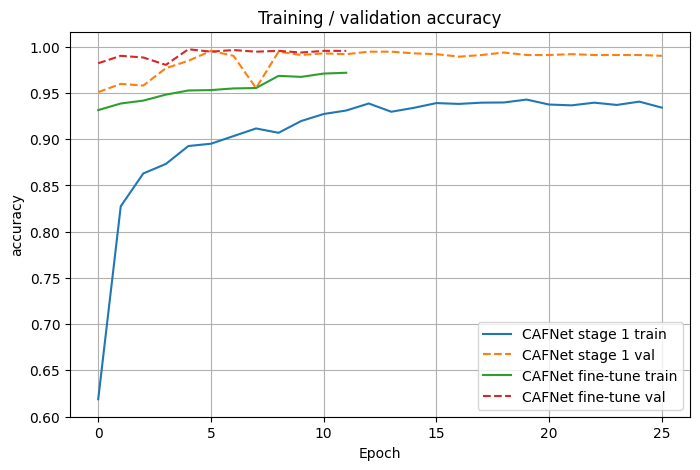

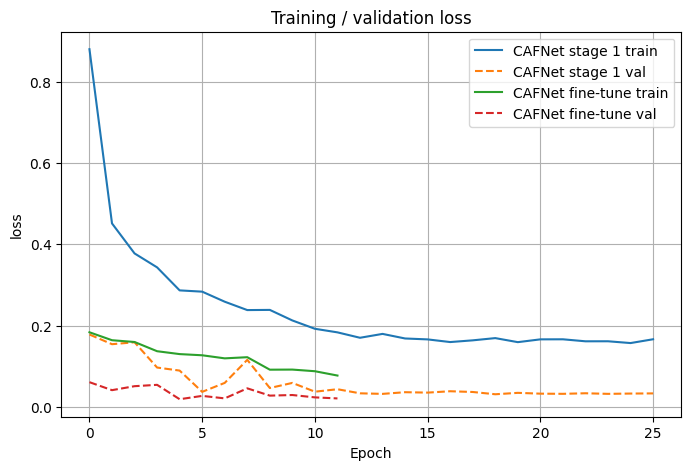

In [13]:
def plot_history(histories, metric="accuracy"):
    plt.figure(figsize=(8,5))
    for label, history in histories:
        plt.plot(history.history.get(metric, []), label=f"{label} train")
        val_key = "val_" + metric
        plt.plot(history.history.get(val_key, []), linestyle="--", label=f"{label} val")
    plt.xlabel("Epoch"); plt.ylabel(metric); plt.title(f"Training / validation {metric}")
    plt.legend(); plt.grid(True); plt.show()

plot_history([("CAFNet stage 1", caf_history), ("CAFNet fine-tune", fine_tune_history)])
plot_history([("CAFNet stage 1", caf_history), ("CAFNet fine-tune", fine_tune_history)], "loss")

## 11. Evaluate once on the untouched test set

This is the final test evaluation. If you change architecture or hyperparameters after seeing this result, create a new independent test set for an unbiased final estimate.

In [14]:
test_loss, test_acc = caf_model.evaluate(test_ds, verbose=1)
print(f"CAFNet test loss: {test_loss:.4f}")
print(f"CAFNet test accuracy: {test_acc*100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - accuracy: 0.8306 - loss: 0.7336
CAFNet test loss: 0.7336
CAFNet test accuracy: 83.06%


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step
              precision    recall  f1-score   support

      glioma     0.9449    0.6425    0.7649       400
  meningioma     0.8023    0.6900    0.7419       400
     notumor     0.8844    0.9950    0.9365       400
   pituitary     0.7453    0.9950    0.8522       400

    accuracy                         0.8306      1600
   macro avg     0.8442    0.8306    0.8239      1600
weighted avg     0.8442    0.8306    0.8239      1600



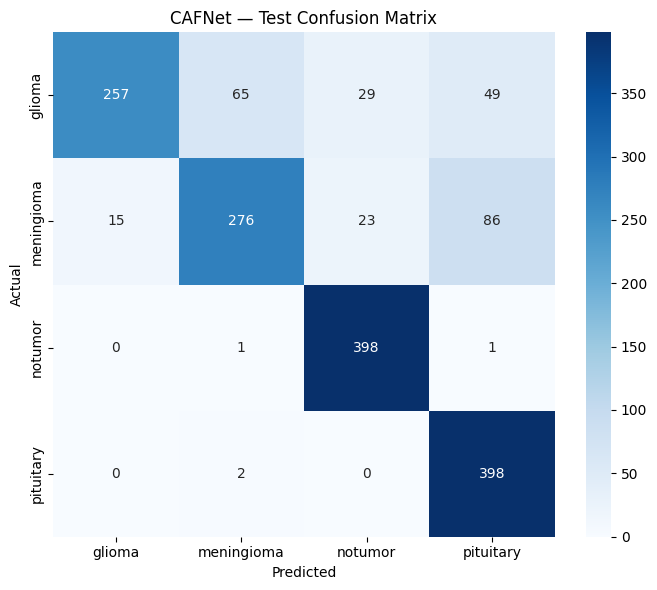

In [15]:
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_prob = caf_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("CAFNet — Test Confusion Matrix")
plt.tight_layout(); plt.show()

## 12. Optional ablation experiment

Run the three comparison models to reproduce the paper's ablation structure. This takes additional GPU time. For a fair comparison, all models use the same train/validation/test partitions and should receive comparable tuning budgets.

In [16]:
RUN_ABLATIONS = False  # Change to True when you have enough Colab GPU time.
ablation_results = {"CAFNet": float(test_acc)}

if RUN_ABLATIONS:
    for mode in ["mobilenet", "vit", "concat"]:
        model, hist, backbone = train_model(mode, epochs=25, lr=1e-4)
        loss, acc = model.evaluate(test_ds, verbose=0)
        ablation_results[mode] = float(acc)
        print(mode, f"test accuracy: {acc*100:.2f}%")
        model.save(f"{mode}_final.keras")

print(pd.DataFrame([
    {"Model": k, "Test Accuracy (%)": v*100}
    for k, v in ablation_results.items()
]).sort_values("Test Accuracy (%)", ascending=False))

    Model  Test Accuracy (%)
0  CAFNet            83.0625


## 13. Save the trained model and class labels

In [17]:
caf_model.save("CAFNet_brain_tumor.keras")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved CAFNet_brain_tumor.keras and class_names.json")

Saved CAFNet_brain_tumor.keras and class_names.json


## 14. Predict a single MRI image

Upload an MRI image and run the cell. The output is a model prediction, not a medical diagnosis.

In [18]:
from google.colab import files
uploaded = files.upload()

Saving mri.jpg to mri.jpg


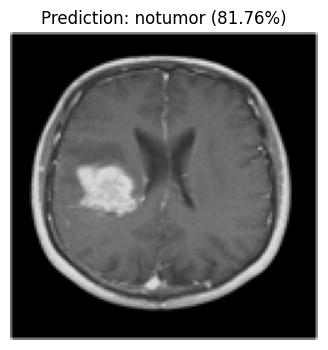

     Class  Probability (%)
   notumor        81.757233
meningioma        18.214430
    glioma         0.020541
 pituitary         0.007794


In [19]:
from PIL import Image
for filename in uploaded:
    img = Image.open(filename).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.asarray(img, dtype=np.float32)
    probs = caf_model.predict(arr[None, ...], verbose=0)[0]
    idx = int(np.argmax(probs))
    plt.figure(figsize=(4,4))
    plt.imshow(img); plt.axis("off")
    plt.title(f"Prediction: {class_names[idx]} ({probs[idx]*100:.2f}%)")
    plt.show()
    print(pd.DataFrame({"Class": class_names, "Probability (%)": probs*100})
          .sort_values("Probability (%)", ascending=False).to_string(index=False))

## 15. Research notes, limitations and reporting

- Paper-reported result: 96.41% test accuracy in the abstract and ablation discussion; its conclusion states 96.81%. These values are internally inconsistent in the article.
- The paper describes a 5,712-image training set and 1,311-image test set. Current Kaggle revisions may have different counts and split composition. Always record the downloaded dataset version and counts.
- This notebook uses the Kaggle-provided `Training/` and `Testing/` directories. It does not merge them or move test images into training.
- The paper discusses 5-fold validation (96.08% ± 0.47%) and external Figshare evaluation (95.60%). Those results are not reproduced merely by running this notebook.
- Architecture choices not fully specified by the article (patch size, embedding width, transformer depth, optimizer schedule, fine-tuning strategy) are stated in code so that the experiment is reproducible, but they should not be represented as the authors' exact unpublished settings.
- Dataset-level accuracy is not clinical validation. Do not use this model to diagnose or make treatment decisions.

### Paper and dataset references
1. Jayaraman, G. et al. “A hybrid CNN–ViT framework with cross-attention fusion and data augmentation for robust brain tumor classification.” *Scientific Reports* 15, 45769 (2025). https://doi.org/10.1038/s41598-025-28636-9
2. Kaggle dataset: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset/data

In [20]:
# ==========================================
# CHECK 1: DUPLICATE IMAGES BETWEEN DATASETS
# ==========================================

import pathlib
import hashlib
from collections import defaultdict

VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def get_image_hash(path):
    with open(path, "rb") as file:
        return hashlib.sha256(file.read()).hexdigest()

train_hashes = defaultdict(list)
test_hashes = defaultdict(list)

# Scan training and testing images
for folder, hash_dict in [
    (TRAIN_DIR, train_hashes),
    (TEST_DIR, test_hashes)
]:
    for img_path in pathlib.Path(folder).rglob("*"):
        if img_path.suffix.lower() in VALID_EXTS:
            try:
                image_hash = get_image_hash(img_path)
                hash_dict[image_hash].append(str(img_path))
            except Exception as e:
                print("Error:", img_path, e)

# Find exact duplicates
duplicates = set(train_hashes.keys()) & set(test_hashes.keys())

print("Total training images:", sum(map(len, train_hashes.values())))
print("Total testing images:", sum(map(len, test_hashes.values())))
print("Exact duplicate images:", len(duplicates))

for h in list(duplicates)[:10]:
    print("\nTRAIN:", train_hashes[h][0])
    print("TEST :", test_hashes[h][0])

Total training images: 5600
Total testing images: 1600
Exact duplicate images: 0


In [21]:
test_loss, test_acc = caf_model.evaluate(test_ds, verbose=1)

print(f"CAFNet test loss: {test_loss:.4f}")
print(f"CAFNet test accuracy: {test_acc*100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.8306 - loss: 0.7336
CAFNet test loss: 0.7336
CAFNet test accuracy: 83.06%


In [23]:
import tensorflow as tf
from tensorflow import keras
import json

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow:", tf.__version__)
print("Preprocessing function loaded successfully!")

TensorFlow: 2.21.0
Preprocessing function loaded successfully!


In [24]:
caf_model = keras.models.load_model(
    "CAFNet_brain_tumor.keras",
    custom_objects={
        "PatchEmbedding": PatchEmbedding,
        "TransformerBlock": TransformerBlock,
        "preprocess_input": preprocess_input
    },
    compile=False
)

caf_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CAFNet model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'vit_encoder_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


CAFNet model loaded successfully!


In [25]:
test_loss, test_acc = caf_model.evaluate(test_ds, verbose=1)

print(f"CAFNet Test Loss: {test_loss:.4f}")
print(f"CAFNet Test Accuracy: {test_acc * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.8306 - loss: 0.7336
CAFNet Test Loss: 0.7336
CAFNet Test Accuracy: 83.06%


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step
              precision    recall  f1-score   support

      glioma     0.9449    0.6425    0.7649       400
  meningioma     0.8023    0.6900    0.7419       400
     notumor     0.8844    0.9950    0.9365       400
   pituitary     0.7453    0.9950    0.8522       400

    accuracy                         0.8306      1600
   macro avg     0.8442    0.8306    0.8239      1600
weighted avg     0.8442    0.8306    0.8239      1600



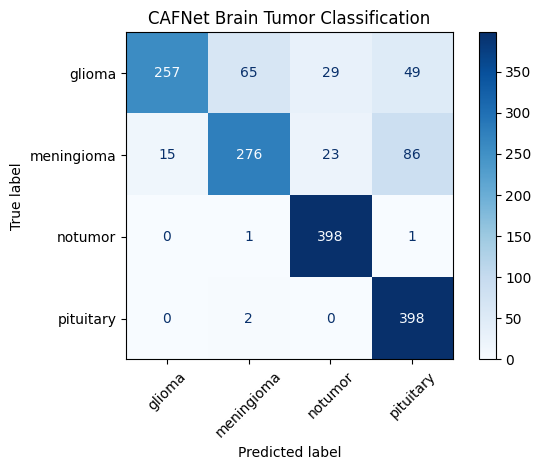

In [26]:
# classification report
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Model predictions
y_pred_probs = caf_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("CAFNet Brain Tumor Classification")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()